# 54 — Interval labels for CYP2D6's unpromoted compounds: one arm, one-sided bound, scored on the unchanged surface

### What changed since notebook 53

Notebook 53's gate tested the **V2 validation surface** — the apparatus for measuring the remedy,
not the remedy. It failed, and the stop rule written into that brief treated the failure as
rejecting the hypothesis. It does not. Notebook 53's own `verdict.json` recorded the cheaper
decisive test, and this notebook runs it: **one arm against notebook 37's existing `mae_only`,
scored on the unchanged V1 surface** — held-out compounds that have real dose-response curves —
paired on the frozen cluster-disjoint partition. No interval window enters the scoring side, so
nothing the gate rejected can reach this comparison.

Notebook 53 also removed the obstacle that would otherwise have blocked the training side. A
*fitted* window is not available on CYP2D6: zero promoted compounds carry a no-inhibition readout
and 91.9% of its excluded compounds sit in that bin, because the hard cut at `log2FC < −0.613`
destroys exactly the data needed to calibrate one. The **unfitted bound** notebook 53 measured
instead — the assay's own detection limit — is what this arm uses.

### The arm

`interval_2d6` is identical to `mae_only` in every respect except one column. For each compound
that is unpromoted on CYP2D6 **and** carries a no-inhibition readout, its `NaN` CYP2D6 label
becomes the bound. Everything else is untouched: curve-bearing rows keep their literal labels on
all four isoforms, unpromoted compounds with intermediate readouts stay `NaN`, and the other three
isoforms' columns are not modified at all. No rows are added — notebook 23 established the screen's
compounds are a strict subset of the curated 4,905.

That single-variable claim is not asserted, it is **proved**: this notebook reconstructs all 25 of
`mae_only`'s own training tables and checks them byte-for-byte against the files that actually
produced the comparator, before building anything.

### Scope and standing rules

Never opened or executed: `notebooks/32_deadzone_aid_retrain.ipynb`,
`notebooks/40_single_object_ensemble.ipynb`, `notebooks/47_mae_only_full_retrain.ipynb` (its
submission cell is live uncommented code). Read-only: `data/`, `src/`, every prior notebook's
`outputs/` tree, `docs/leaderboard_submissions.md`. Four-test scope check at the end.
`OMP_NUM_THREADS` asserted unset; `KMP_DUPLICATE_LIB_OK` reported, not asserted. Kernelspec pinned
to `cyp-admet-v2`. Fold file sha256 asserted.

In [1]:
import os

# OMP_NUM_THREADS is asserted unset: notebook 34 established that restricting BLAS/OMP to one
# thread changes floating-point reduction order and so Chemprop's training trajectory, breaking
# bit-reproducibility against notebook 05's stored scores. KMP_DUPLICATE_LIB_OK is only REPORTED --
# `import xgboost` sets it (notebook 52), so asserting it unset below any import is unsatisfiable.
assert "OMP_NUM_THREADS" not in os.environ, (
    "OMP_NUM_THREADS is set in this kernel. Unset it and restart before running this notebook.")
print("OMP_NUM_THREADS: unset (asserted)")
print(f"KMP_DUPLICATE_LIB_OK: {os.environ.get('KMP_DUPLICATE_LIB_OK','unset')} "
      f"(reported, not asserted)")

import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

import hashlib, importlib.metadata, inspect, itertools, json, subprocess, time
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src.features import assign_screen_split, smiles_to_inchikey
from src.chemprop_screen import (build_predict_csv, build_training_csv, load_screen_population,
                                 run_chemprop_predict, run_chemprop_train, setup_logging,
                                 verify_predictions)
from src.cv_bootstrap import per_fold_bootstrap_seed
from src.vendor.openadmet_eval.config import ACTIVITY_METRICS, REGRESSION_ENDPOINTS
from src.vendor.openadmet_eval.evaluate_predictions import (add_macro_endpoint,
                                                            score_activity_predictions)
from src.ash_protocol import levene_check, rm_anova

from loguru import logger as _loguru
_loguru.remove()

print(f"\npython {sys.version.split()[0]}  exe {sys.executable}")
for p in ["numpy", "pandas", "scipy", "rdkit", "chemprop", "torch", "scikit-learn"]:
    try: print(f"  {p}: {importlib.metadata.version(p)}")
    except importlib.metadata.PackageNotFoundError: pass
assert importlib.metadata.version("rdkit").startswith("2026.3.3")

ISO = [e.split("_")[0] for e in REGRESSION_ENDPOINTS]
EP = {i: f"{i}_pIC50_direct_inhibition" for i in ISO}
METRICS = [n for n, _ in ACTIVITY_METRICS]

OUT = REPO / "outputs" / "54_interval_2d6_arm"
FIG, PRED_DIR, SCORE_DIR, RUNS = OUT / "figures", OUT / "predictions", OUT / "scores", OUT / "chemprop_runs"
LOGD = REPO / "logs" / "54_interval_2d6_arm"
for d in [OUT, FIG, PRED_DIR, SCORE_DIR, RUNS, LOGD]:
    d.mkdir(parents=True, exist_ok=True)

RUN_STARTED_AT = datetime.now(timezone.utc)
_pre = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
PRE_DIRTY = sorted(l[3:].strip() for l in _pre.stdout.splitlines() if not l.startswith("??"))
(OUT / "run_meta.json").write_text(json.dumps(
    {"run_started_at_utc": RUN_STARTED_AT.isoformat(),
     "pre_existing_dirty_tracked_paths": PRE_DIRTY}, indent=1) + "\n")
print(f"\nRUN_STARTED_AT {RUN_STARTED_AT.isoformat()}")
print(f"pre-existing dirty tracked paths: {PRE_DIRTY if PRE_DIRTY else 'none'}")

DECISIONS = []
def decide(what, chose, why, alternative):
    DECISIONS.append({"decision": what, "chose": chose, "why": why, "alternative": alternative})
    print(f"\n[DECISION] {what}\n  chose: {chose}\n  why: {why}\n  alternative: {alternative}")

OMP_NUM_THREADS: unset (asserted)
KMP_DUPLICATE_LIB_OK: unset (reported, not asserted)



python 3.11.13  exe /Users/codiefreeman/miniconda3-arm64/envs/cyp-admet-v2/bin/python
  numpy: 1.26.4
  pandas: 2.3.3
  scipy: 1.17.1
  rdkit: 2026.3.3
  chemprop: 2.3.1
  torch: 2.13.0
  scikit-learn: 1.9.0

RUN_STARTED_AT 2026-10-19T21:49:21.086745+00:00
pre-existing dirty tracked paths: ['CLAUDE.md']


## Part 0 — Sanity and provenance

Three checks before anything is built, in increasing strength: the partition is the frozen file,
the Chemprop training path still reproduces notebook 05 bit-for-bit, and — the one that actually
secures this comparison — every one of `mae_only`'s 25 training tables can be reconstructed
**byte-identically** from this notebook's own code.

In [2]:
# ---- Part 0.1: paths, the frozen partition, seeds, and WHERE EACH ARM'S FOLDS LIVE.
CURATED_PATH = REPO / "data" / "processed" / "train_inhibition_curated.csv"
BLIND_PATH = REPO / "data" / "processed" / "test_blinded_curated.csv"
SINGLECONC_PATH = REPO / "data" / "raw" / "cyp-challenge-single-concentration-TRAIN.csv"
RANDOM_FOLDS_PATH = REPO / "data" / "folds" / "cv_folds.csv"
BUTINA5X5_PATH = REPO / "data" / "folds" / "cv_folds_butina_5x5.csv"
NB05, NB34, NB35, NB37 = (REPO / "outputs" / d for d in
    ["05_cv_comparison", "34_butina_5x5", "35_butina_repeat3", "37_butina_5x5_complete"])

BUTINA5X5_SHA = "52f39b1a1cea9200b58dce0a061d4a21ce94d9d58ec77067cf6508b0f4b3e87e"
VAL_FRACTION, EPOCHS, PATIENCE, N_FOLDS = 0.15, 50, 5, 5
SANITY_THRESHOLD = 0.03
BASE_COLS = ["Molecule_Name", "inchikey", "canonical_smiles"]
CHEMELEON_ARCH_ARGS = ["--from-foundation", "CHEMELEON", "--multi-hot-atom-featurizer-mode", "V2"]
MAE_ARCH_ARGS = CHEMELEON_ARCH_ARGS + ["--loss-function", "mae"]
PLAIN_ARCH_ARGS = CHEMELEON_ARCH_ARGS + ["--loss-function", "mse"]

sha = hashlib.sha256(BUTINA5X5_PATH.read_bytes()).hexdigest()
assert sha == BUTINA5X5_SHA, f"fold file sha256 {sha} != {BUTINA5X5_SHA}"
print(f"cv_folds_butina_5x5.csv sha256 CONFIRMED {sha[:16]}...")

curated = pd.read_csv(CURATED_PATH)
blind = pd.read_csv(BLIND_PATH)
folds5 = pd.read_csv(BUTINA5X5_PATH)
REPEAT_COLS = {r: f"butina_repeat_{r}" for r in range(5)}
assert all(c in folds5.columns for c in REPEAT_COLS.values())
assert len(curated) == 4905 and len(blind) == 750
assert set(folds5.inchikey) == set(curated.inchikey)
print(f"curated {curated.shape}  blind {blind.shape}")

# mae loss confirmed against the installed API, not assumed from the flag name (notebook 31's check).
import chemprop.nn as cp_nn
assert "(preds-targets).abs()" in inspect.getsource(
    cp_nn.LossFunctionRegistry["mae"]).replace(" ", "")
print("chemprop 'mae' confirmed to compute (preds - targets).abs()")

# Seeds, from notebook 05's manifest, cross-checked against 34/35/37's own record.
mf = pd.read_csv(NB05 / "manifest.csv")
mf = mf[mf.config == "chemprop_chemeleoninit"].sort_values(["repeat", "fold"])
assert len(mf) == 25
FOLD_SEED = {(int(r.repeat), int(r.fold)): int(r.seed) for r in mf.itertuples()}
assert [FOLD_SEED[(0, f)] for f in range(3)] == [2684470948, 4091952314, 233227757]
prior = {}
for d in [NB34, NB35, NB37]:
    rs = pd.read_csv(d / "run_scores.csv")[["repeat", "fold", "seed"]].drop_duplicates()
    prior.update(rs.set_index(["repeat", "fold"])["seed"].to_dict())
assert not [k for k, v in prior.items() if FOLD_SEED[k] != v], "seed mapping differs from 34/35/37"
print(f"{len(prior)} (repeat, fold) seeds match notebooks 34/35/37 exactly")

# A SECOND CORRECTED PREMISE. Notebook 53 corrected the brief's claim that all 25 folds of
# predictions sit in notebook 37's directory. The task for THIS notebook carries that correction
# forward but applies one map to BOTH arms: repeats 0-1 in 34, repeat 2 in 35, repeats 3-4 in 37.
# That is true of `plain` and FALSE of `mae_only`, whose repeats 0, 1 AND 2 are all notebook 35's
# (35 added the mae_only arm across all three pre-existing repeats; 34 never ran it). Measured
# from the filesystem rather than assumed, per arm.
ARM_DIR = {}
for arm in ["plain", "mae_only"]:
    m = {}
    for r in range(5):
        for d in [NB34, NB35, NB37]:
            if (d / "predictions" / f"{arm}__r{r}f0.csv").exists():
                m[r] = d / "predictions"; break
        assert r in m, f"no directory holds {arm} repeat {r}"
    ARM_DIR[arm] = m
    print(f"\n{arm}: " + "  ".join(f"r{r}->{m[r].parent.name.split('_')[0]}" for r in range(5)))
assert ARM_DIR["plain"][0].parent.name.startswith("34")
assert ARM_DIR["mae_only"][0].parent.name.startswith("35"), \
    "mae_only repeat 0 is expected in notebook 35, not 34"
for arm, m in ARM_DIR.items():
    cells = {(r, f) for r in range(5) for f in range(N_FOLDS)
             if (m[r] / f"{arm}__r{r}f{f}.csv").exists()}
    assert len(cells) == 25, f"{arm}: found {len(cells)} (repeat, fold) cells, expected 25"
print("\nboth arms assembled to 25 distinct (repeat, fold) cells, asserted.")

cv_folds_butina_5x5.csv sha256 CONFIRMED 52f39b1a1cea9200...
curated (4905, 20)  blind (750, 4)


chemprop 'mae' confirmed to compute (preds - targets).abs()
25 (repeat, fold) seeds match notebooks 34/35/37 exactly

plain: r0->34  r1->34  r2->35  r3->37  r4->37

mae_only: r0->35  r1->35  r2->35  r3->37  r4->37

both arms assembled to 25 distinct (repeat, fold) cells, asserted.


In [3]:
# ---- Part 0.2: Chemprop sanity run -- PLAIN on the RANDOM partition's repeat_0/fold_0 against
# notebook 05's stored scores. Twelfth consecutive notebook to run this. Cached on its own output.
_env_bin = str(Path(sys.executable).parent)
if _env_bin not in os.environ.get("PATH", "").split(os.pathsep):
    os.environ["PATH"] = os.pathsep.join([_env_bin, *os.environ.get("PATH", "").split(os.pathsep)])

SANITY_TAG = "sanity_plain__random_r0f0"
sanity_seed = FOLD_SEED[(0, 0)]
slog = setup_logging(LOGD / f"{SANITY_TAG}.log", f"nb54_{SANITY_TAG}")
spath = OUT / f"{SANITY_TAG}.csv"
spop = load_screen_population(RANDOM_FOLDS_PATH, CURATED_PATH, "repeat_0", 0,
                              VAL_FRACTION, sanity_seed, slog)
sexp = set(spop.loc[spop.screen_split == "screen_test", "Molecule_Name"])

if spath.exists() and set(pd.read_csv(spath)["Molecule_Name"]) == sexp:
    print(f"[cache hit] {SANITY_TAG}")
    spred = pd.read_csv(spath)
else:
    rd = RUNS / SANITY_TAG; rd.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    build_training_csv(spop, list(REGRESSION_ENDPOINTS), rd / "train_input.csv", slog,
                       require_all_targets=False)
    pcsv = build_predict_csv(spop, rd, slog)
    run_chemprop_train(rd / "train_input.csv", list(REGRESSION_ENDPOINTS), rd, slog,
                       PLAIN_ARCH_ARGS, EPOCHS, PATIENCE, sanity_seed)
    run_chemprop_predict(rd / "model_0", pcsv, rd / "raw_predictions.csv", slog)
    verify_predictions(rd / "raw_predictions.csv", sexp, list(REGRESSION_ENDPOINTS), slog)
    spred = pd.read_csv(rd / "raw_predictions.csv"); spred.to_csv(spath, index=False)
    print(f"sanity run: {(time.time()-t0)/60:.2f} min")

with per_fold_bootstrap_seed(sanity_seed):
    mine = (score_activity_predictions(spred, curated[curated.inchikey.isin(spred.inchikey)].copy(),
                                       list(REGRESSION_ENDPOINTS))
            .groupby("Endpoint")["ST-RAE"].mean())
theirs = (pd.read_csv(NB05 / "scores" / "chemprop_chemeleoninit__repeat0_fold0.csv")
          .groupby("Endpoint")["ST-RAE"].mean())
rows, mx = [], 0.0
print(f"\nSANITY -- PLAIN on random repeat_0/fold_0 vs notebook 05's stored scores")
for ep in sorted(set(mine.index) & set(theirs.index)):
    d = abs(float(mine[ep]) - float(theirs[ep])); mx = max(mx, d)
    print(f"  {ep:40s} {mine[ep]:.10f}  {theirs[ep]:.10f}  diff {d:.3e}")
    rows.append({"Endpoint": ep, "this_run": float(mine[ep]), "nb05": float(theirs[ep]), "abs_diff": d})
pd.DataFrame(rows).to_csv(OUT / "sanity_check.csv", index=False)
print(f"max abs diff {mx:.3e} (threshold {SANITY_THRESHOLD})")
assert mx <= SANITY_THRESHOLD, f"SANITY FAILED: {mx:.6f} > {SANITY_THRESHOLD}"
print("PASS -- the twelfth notebook in a row to reproduce notebook 05's own stored numbers.")

2026-10-19 22:49:23,732 [INFO] loaded cv_folds.csv: (4905, 7)


2026-10-19 22:49:23,732 [INFO] loaded train_inhibition_curated.csv: (4905, 20)


2026-10-19 22:49:23,739 [INFO] assign_screen_split(repeat_col='repeat_0', test_fold=0, val_fraction=0.15, seed=2684470948) split counts: {'screen_inner_train': 3335, 'screen_test': 981, 'screen_inner_val': 589}


2026-10-19 22:49:23,741 [INFO] rows after SMILES/target join: 4905 (missing: 0)


2026-10-19 22:49:23,742 [INFO]   CYP1A2_pIC50_direct_inhibition: labeled-compound counts per split = {'screen_inner_train': 975, 'screen_inner_val': 160, 'screen_test': 277}


2026-10-19 22:49:23,743 [INFO]   CYP2C9_pIC50_direct_inhibition: labeled-compound counts per split = {'screen_inner_train': 861, 'screen_inner_val': 160, 'screen_test': 264}


2026-10-19 22:49:23,744 [INFO]   CYP2D6_pIC50_direct_inhibition: labeled-compound counts per split = {'screen_inner_train': 1017, 'screen_inner_val': 181, 'screen_test': 295}


2026-10-19 22:49:23,745 [INFO]   CYP3A4_pIC50_direct_inhibition: labeled-compound counts per split = {'screen_inner_train': 1604, 'screen_inner_val': 281, 'screen_test': 450}


[cache hit] sanity_plain__random_r0f0



SANITY -- PLAIN on random repeat_0/fold_0 vs notebook 05's stored scores
  CYP1A2_pIC50_direct_inhibition           0.7883875413  0.7883875413  diff 0.000e+00
  CYP2C9_pIC50_direct_inhibition           0.7113010721  0.7113010721  diff 0.000e+00
  CYP2D6_pIC50_direct_inhibition           0.9580366078  0.9580366078  diff 0.000e+00
  CYP3A4_pIC50_direct_inhibition           0.4910353466  0.4910353466  diff 0.000e+00
max abs diff 0.000e+00 (threshold 0.03)
PASS -- the twelfth notebook in a row to reproduce notebook 05's own stored numbers.


In [4]:
# ---- Part 0.3: the check that actually secures this comparison. Reconstruct ALL 25 of mae_only's
# training tables with this notebook's own code and compare byte-for-byte against the files that
# produced the comparator. If these match, `interval_2d6` differs from `mae_only` in exactly the
# cells this notebook changes and in nothing else -- proved, not asserted.
def build_population(repeat, fold, seed, target_source):
    """mae_only's own construction (notebook 37 cell 13), minus the AID branch this arm never
    uses. `target_source` supplies the four scored columns; passing `curated` reproduces mae_only."""
    split_df = assign_screen_split(folds5, repeat_col=REPEAT_COLS[repeat], test_fold=fold,
                                   val_fraction=VAL_FRACTION, seed=seed)
    pop = curated[BASE_COLS].copy().merge(
        target_source[["inchikey"] + list(REGRESSION_ENDPOINTS)], on="inchikey", how="left")
    assert len(pop) == len(curated), "target merge changed row count"
    pop = pop.merge(split_df[["inchikey", "screen_split"]], on="inchikey", how="left")
    assert len(pop) == len(curated), "split merge changed row count"
    pop.loc[pop.screen_split.isna(), "screen_split"] = "screen_inner_train"
    assert pop.screen_split.isin(["screen_test", "screen_inner_train", "screen_inner_val"]).all()
    return pop

_vlog = setup_logging(LOGD / "verify_mae_only.log", "nb54_verify")
_tmp = OUT / "_verify_tmp"; _tmp.mkdir(exist_ok=True)
MAE_RUN_DIR = {r: (NB35 if r <= 2 else NB37) / "chemprop_runs" for r in range(5)}
ok, bad = 0, []
for r in range(5):
    for f in range(N_FOLDS):
        pop = build_population(r, f, FOLD_SEED[(r, f)], curated)
        p = _tmp / f"r{r}f{f}.csv"
        build_training_csv(pop, list(REGRESSION_ENDPOINTS), p, _vlog, require_all_targets=False)
        theirs_p = MAE_RUN_DIR[r] / f"mae_only__r{r}f{f}" / "train_input.csv"
        assert theirs_p.exists(), f"missing {theirs_p}"
        if hashlib.sha256(p.read_bytes()).hexdigest() == hashlib.sha256(theirs_p.read_bytes()).hexdigest():
            ok += 1
        else:
            bad.append((r, f))
print(f"mae_only training tables reproduced BYTE-IDENTICALLY: {ok}/25")
assert ok == 25, f"mismatch on {bad} -- this notebook's construction is NOT mae_only's"
print("So any difference between interval_2d6 and mae_only comes from the one column this")
print("notebook changes, and from nothing else in the construction path.")
import shutil; shutil.rmtree(_tmp)

2026-10-19 22:49:26,236 [INFO] r0f0.csv: pooled-train rows before label filter=3924, after=3924 (require_all_targets=False, targets=['CYP1A2_pIC50_direct_inhibition', 'CYP2C9_pIC50_direct_inhibition', 'CYP2D6_pIC50_direct_inhibition', 'CYP3A4_pIC50_direct_inhibition'])


2026-10-19 22:49:26,245 [INFO] wrote /Users/codiefreeman/OpenADMET-CYP-Blind-Challenge/outputs/54_interval_2d6_arm/_verify_tmp/r0f0.csv (3924 rows, chemprop_split counts: {'train': 3335, 'val': 589})


2026-10-19 22:49:26,251 [INFO] r0f1.csv: pooled-train rows before label filter=3924, after=3924 (require_all_targets=False, targets=['CYP1A2_pIC50_direct_inhibition', 'CYP2C9_pIC50_direct_inhibition', 'CYP2D6_pIC50_direct_inhibition', 'CYP3A4_pIC50_direct_inhibition'])


2026-10-19 22:49:26,259 [INFO] wrote /Users/codiefreeman/OpenADMET-CYP-Blind-Challenge/outputs/54_interval_2d6_arm/_verify_tmp/r0f1.csv (3924 rows, chemprop_split counts: {'train': 3335, 'val': 589})


2026-10-19 22:49:26,264 [INFO] r0f2.csv: pooled-train rows before label filter=3924, after=3924 (require_all_targets=False, targets=['CYP1A2_pIC50_direct_inhibition', 'CYP2C9_pIC50_direct_inhibition', 'CYP2D6_pIC50_direct_inhibition', 'CYP3A4_pIC50_direct_inhibition'])


2026-10-19 22:49:26,272 [INFO] wrote /Users/codiefreeman/OpenADMET-CYP-Blind-Challenge/outputs/54_interval_2d6_arm/_verify_tmp/r0f2.csv (3924 rows, chemprop_split counts: {'train': 3335, 'val': 589})


... (41 outputs left out)

2026-10-19 22:49:26,568 [INFO] wrote /Users/codiefreeman/OpenADMET-CYP-Blind-Challenge/outputs/54_interval_2d6_arm/_verify_tmp/r4f3.csv (3924 rows, chemprop_split counts: {'train': 3335, 'val': 589})


2026-10-19 22:49:26,574 [INFO] r4f4.csv: pooled-train rows before label filter=3924, after=3924 (require_all_targets=False, targets=['CYP1A2_pIC50_direct_inhibition', 'CYP2C9_pIC50_direct_inhibition', 'CYP2D6_pIC50_direct_inhibition', 'CYP3A4_pIC50_direct_inhibition'])


2026-10-19 22:49:26,582 [INFO] wrote /Users/codiefreeman/OpenADMET-CYP-Blind-Challenge/outputs/54_interval_2d6_arm/_verify_tmp/r4f4.csv (3924 rows, chemprop_split counts: {'train': 3335, 'val': 589})


mae_only training tables reproduced BYTE-IDENTICALLY: 25/25
So any difference between interval_2d6 and mae_only comes from the one column this
notebook changes, and from nothing else in the construction path.


## Part 1 — The bound, from the file rather than the nominal concentration

A compound showing no inhibition at the screen's concentration has, by construction, an IC50 above
that concentration — so its pIC50 is below `−log₁₀(concentration)`. That is a physical bound, not
a fitted one, which is exactly why it survives where notebook 53's fitted window could not be
calibrated at all on CYP2D6.

The concentration is read from the file's own column. A *nominal* 50 µM would give 4.3010; the
file says 4.95049505 × 10⁻⁵ M, giving **4.3054**. The two disagree by 0.0043 and the file's own
column is the correct one.

In [5]:
# ---- Part 1: the bound and the no-inhibition bin, re-derived from the release.
sc_raw = pd.read_csv(SINGLECONC_PATH)
conc = sc_raw.concentration_M.unique()
assert len(conc) == 1, f"file is not single-concentration: {conc}"
CONC_M = float(conc[0])
BOUND = float(-np.log10(CONC_M))
NOMINAL = float(-np.log10(50e-6))
print(f"concentration_M (from the file) = {CONC_M:.10e}")
print(f"  bound = -log10(conc)          = {BOUND:.6f}")
print(f"  a NOMINAL 50 uM would give      {NOMINAL:.6f}   (differs by {BOUND-NOMINAL:+.4f})")
assert abs(BOUND - 4.3054) < 5e-5, f"bound {BOUND:.6f} does not reproduce notebook 53's 4.3054"
print(f"  reproduces notebook 53's 4.3054: YES")

NOINH_LOG2FC = float(np.log2(0.9))     # r = 2^log2fc >= 0.9, notebook 53's own edge
print(f"\nno-inhibition bin edge: r >= 0.9  <->  log2FC >= {NOINH_LOG2FC:.6f}")

sc_uniq = sc_raw[["Molecule_Name", "SMILES"]].drop_duplicates("Molecule_Name").reset_index(drop=True)
sc_uniq["inchikey"] = [smiles_to_inchikey(s) for s in sc_uniq.SMILES]
assert sc_uniq.inchikey.isna().sum() == 0
SCREEN = (sc_raw.merge(sc_uniq[["Molecule_Name", "inchikey"]], on="Molecule_Name", how="left")
          .pivot_table(index="inchikey", columns="enzyme", values="log2fc_estimate", aggfunc="mean"))
assert set(SCREEN.index) <= set(curated.inchikey), "screen is not a strict subset of curated"
print(f"screen: {len(SCREEN)} compounds, strict subset of the curated 4,905 (notebook 23)")

d2d6 = pd.DataFrame({"log2fc": SCREEN["CYP2D6"]}).join(
    curated.set_index("inchikey")[EP["CYP2D6"]].rename("pic50"))
unprom = d2d6[d2d6.pic50.isna()]
NOINH_IK = set(unprom.index[unprom.log2fc >= NOINH_LOG2FC])
print(f"\nCYP2D6: screened {len(d2d6)}, with a curve {int(d2d6.pic50.notna().sum())}, "
      f"unpromoted {len(unprom)}")
print(f"  of the unpromoted, NO-INHIBITION readout: {len(NOINH_IK)} "
      f"({len(NOINH_IK)/len(unprom):.1%})   <- these get the bound")
print(f"  intermediate readout, stay NaN:           {len(unprom) - len(NOINH_IK)}")
assert len(unprom) == 2882 and len(NOINH_IK) == 2648, \
    f"expected 2,648 of 2,882 (notebook 53); got {len(NOINH_IK)} of {len(unprom)}"
n_before = int(curated[EP["CYP2D6"]].notna().sum())
print(f"\nCYP2D6 labelled count: {n_before} -> {n_before + len(NOINH_IK)} "
      f"(x{(n_before+len(NOINH_IK))/n_before:.2f})")
print(f"existing CYP2D6 labels that fall BELOW the bound: "
      f"{int((curated[EP['CYP2D6']] < BOUND).sum())}/{n_before} "
      f"({(curated[EP['CYP2D6']] < BOUND).sum()/n_before:.1%})")
print(f"labelled CYP2D6 pIC50 range: {curated[EP['CYP2D6']].min():.3f} to "
      f"{curated[EP['CYP2D6']].max():.3f}")

concentration_M (from the file) = 4.9504950500e-05
  bound = -log10(conc)          = 4.305351
  a NOMINAL 50 uM would give      4.301030   (differs by +0.0043)
  reproduces notebook 53's 4.3054: YES

no-inhibition bin edge: r >= 0.9  <->  log2FC >= -0.152003


screen: 4375 compounds, strict subset of the curated 4,905 (notebook 23)

CYP2D6: screened 4375, with a curve 1493, unpromoted 2882
  of the unpromoted, NO-INHIBITION readout: 2648 (91.9%)   <- these get the bound
  intermediate readout, stay NaN:           234

CYP2D6 labelled count: 1493 -> 4141 (x2.77)
existing CYP2D6 labels that fall BELOW the bound: 229/1493 (15.3%)
labelled CYP2D6 pIC50 range: 1.947 to 7.535


## Part 2 — The arm's training target

### Why a point target at the bound, rather than a clipped band

A clipped (dead-zone) target needs a **donor prediction**, and every out-of-fold donor built from
these 4,905 compounds carries the fold crosstalk that `mae_only` exists to avoid — the donor was
itself trained on the fold being held out. Using one would contaminate the arm's only real virtue,
which is that it is the leak-free half of the dead-zone effect.

A point target at the right-hand end of the window needs no donor and no fitted window. It is also
what talindrew's own decision rule licenses (§5): when every draw says inactive, the risk is flat
across the free window, and the right end is closer to the error that actually occurs.

**The cost is under-correction**, recorded here as a stated limitation rather than discovered
later: a compound genuinely at pIC50 2.0 is pulled only to 4.3054, not to 2.0. That error is
bounded, one-directional, and in the conservative direction.

In [6]:
# ---- Part 2: build the interval target table and prove it is a one-column change.
decide("point target at the bound vs a clipped dead-zone band",
       "point target at BOUND = 4.3054 for every unpromoted CYP2D6 compound with a no-inhibition "
       "readout",
       "a clipped band needs a donor prediction, and every OOF donor available here was itself "
       "trained on the fold being held out -- notebook 31's documented fold crosstalk, which is "
       "precisely what mae_only exists to avoid, so using one would contaminate the arm's only "
       "real virtue. A point target needs no donor and no fitted window (notebook 53 established "
       "no window is calibratable on CYP2D6 anyway), and talindrew's own rule licenses the right "
       "end of a flat-risk window. STATED LIMITATION: it under-corrects -- a compound truly at "
       "pIC50 2.0 is pulled only to 4.3054 -- which is bounded, one-directional and conservative.",
       "clip(donor_prediction, lo, hi) under MAE, as notebooks 31/32 do -- REJECTED for the "
       "crosstalk reason above")

interval_targets = curated[["inchikey"] + list(REGRESSION_ENDPOINTS)].copy()
mask = interval_targets.inchikey.isin(NOINH_IK)
assert interval_targets.loc[mask, EP["CYP2D6"]].isna().all(), \
    "a compound selected for an interval label already carries a CYP2D6 curve"
interval_targets.loc[mask, EP["CYP2D6"]] = BOUND
print(f"interval labels written: {int(mask.sum())}")

# --- the three assertions the task requires, plus the cell-level diff.
# (1) dimensions unchanged -- no rows added (notebook 23: the screen is a strict subset).
assert interval_targets.shape == curated[["inchikey"] + list(REGRESSION_ENDPOINTS)].shape
print(f"(1) table dimensions unchanged: {interval_targets.shape} -- no rows added")

# (2) the four scored columns bit-identical to mae_only's on every curve-bearing row.
for iso in ISO:
    m = curated[EP[iso]].notna()
    a = curated.loc[m, EP[iso]].to_numpy()
    b = interval_targets.loc[m.to_numpy(), EP[iso]].to_numpy()
    assert np.array_equal(a, b), f"{iso}: a curve-bearing label was modified"
print("(2) all four scored columns bit-identical on every curve-bearing row (exact equality)")

# (3) zero blind-750 compounds carry an interval label anywhere.
assert len(NOINH_IK & set(blind.inchikey)) == 0
print("(3) zero blind-750 compounds carry an interval label")

# (4) beyond the three required: the ONLY cells that differ, anywhere in the table.
diff = []
for iso in ISO:
    a, b = curated[EP[iso]], interval_targets[EP[iso]]
    changed = ~((a.isna() & b.isna()) | (a == b))
    if changed.any():
        diff.append((iso, int(changed.sum()), set(curated.loc[changed, "inchikey"])))
assert len(diff) == 1 and diff[0][0] == "CYP2D6", f"more than CYP2D6 changed: {[d[0] for d in diff]}"
assert diff[0][1] == len(NOINH_IK) and diff[0][2] == NOINH_IK
print(f"(4) exactly {diff[0][1]} cells differ, all in CYP2D6, all NaN -> {BOUND:.4f}, "
      f"and they are exactly the no-inhibition set")

newcol = interval_targets[EP["CYP2D6"]]
print(f"\nCYP2D6 training-label composition after the change:")
print(f"  real curve labels : {n_before:5d}  ({n_before/newcol.notna().sum():.1%})")
print(f"  at the bound      : {len(NOINH_IK):5d}  ({len(NOINH_IK)/newcol.notna().sum():.1%})")
print(f"  total labelled    : {int(newcol.notna().sum()):5d}")
print("\nNote the 64% figure: under MAE loss the conditional median is what is optimised, so the")
print("arm is at real risk of compressing its CYP2D6 predictions toward the bound. That risk is")
print("pre-registered as a measured secondary outcome, not as a gate -- see Part 3.")


[DECISION] point target at the bound vs a clipped dead-zone band
  chose: point target at BOUND = 4.3054 for every unpromoted CYP2D6 compound with a no-inhibition readout
  why: a clipped band needs a donor prediction, and every OOF donor available here was itself trained on the fold being held out -- notebook 31's documented fold crosstalk, which is precisely what mae_only exists to avoid, so using one would contaminate the arm's only real virtue. A point target needs no donor and no fitted window (notebook 53 established no window is calibratable on CYP2D6 anyway), and talindrew's own rule licenses the right end of a flat-risk window. STATED LIMITATION: it under-corrects -- a compound truly at pIC50 2.0 is pulled only to 4.3054 -- which is bounded, one-directional and conservative.
  alternative: clip(donor_prediction, lo, hi) under MAE, as notebooks 31/32 do -- REJECTED for the crosstalk reason above
interval labels written: 2648
(1) table dimensions unchanged: (4905, 5) -- no rows

## Part 3 — The pre-registration

Frozen by `scripts/54_freeze_prereg.py`, which **refuses to run if any `interval_2d6` prediction
exists on disk**, so the thresholds provably cannot have been tuned to the arm's result. It is read
back here and checked against the files it was derived from.

In [7]:
# ---- Part 3: read back the frozen pre-registration and verify it preceded the arm.
PREREG = json.loads((OUT / "prereg.json").read_text())
frozen_at = datetime.fromisoformat(PREREG["frozen_at_utc"])
existing_preds = sorted(PRED_DIR.glob("interval_2d6__*.csv"))
if existing_preds:
    earliest = min(datetime.fromtimestamp(p.stat().st_mtime, timezone.utc) for p in existing_preds)
    assert frozen_at < earliest, (
        f"prereg.json ({frozen_at}) post-dates the earliest interval_2d6 prediction ({earliest}) "
        f"-- the freeze did not precede the arm")
    print(f"prereg frozen {frozen_at.isoformat()}, earliest prediction {earliest.isoformat()} -- "
          f"freeze precedes the arm")
else:
    print(f"prereg frozen {frozen_at.isoformat()}; no interval_2d6 predictions exist yet")
assert PREREG["interval_2d6_predictions_present_at_freeze"] == 0
assert PREREG["provenance"]["fold_file_sha256"] == BUTINA5X5_SHA

BAR = {m: PREREG["materiality_bars"][m] for m in ["ST-RAE", "Spearman"]}
print(f"\nmateriality bars (notebook 37's pooled-SE rule, recomputed and asserted in the script):")
for m in BAR:
    print(f"  {m:9s} " + "  ".join(f"{i}={BAR[m][i]:.4f}" for i in ISO))
print(f"\nprimary metric: {PREREG['primary_metric']};  co-primary: {PREREG['co_primary_metric']}")
print(f"\ndirectional prediction (frozen): {PREREG['directional_prediction']}")
print(f"\nINFERENCE ASYMMETRY (frozen before the run):\n  {PREREG['inference_asymmetry_recorded_before_the_run']}")
print(f"\nBUILT-IN CONTROL (frozen):\n  {PREREG['built_in_control']}")
print(f"\nSECONDARY OUTCOME (frozen, not a gate):\n  {PREREG['secondary_outcome_prediction_spread']}")

prereg frozen 2026-10-19T17:01:05.125571+00:00, earliest prediction 2026-10-19T17:24:10.328133+00:00 -- freeze precedes the arm

materiality bars (notebook 37's pooled-SE rule, recomputed and asserted in the script):
  ST-RAE    CYP1A2=0.0234  CYP2C9=0.0209  CYP2D6=0.0277  CYP3A4=0.0160
  Spearman  CYP1A2=0.0183  CYP2C9=0.0160  CYP2D6=0.0212  CYP3A4=0.0100

primary metric: Spearman;  co-primary: ST-RAE

directional prediction (frozen): CYP2D6 should gain. It carries both the strongest promotion filter (AUC of screen activity for promotion = 0.9998) and the strongest over-prediction on the population that filter removed (66.4% of confirmed non-inhibitors predicted above a bound they are known to be below) -- notebook 53 Parts 1 and 3.4.

INFERENCE ASYMMETRY (frozen before the run):
  The target figure (CYP2D6 rho 0.378 -> 0.476) was measured on talindrew's V2 surface, which CONTAINS the interval compounds. V1 does not. V1 asks whether teaching the model where the low end sits improves r

## Part 4 — One arm, 25 folds

`interval_2d6` on the frozen partition: same seeds, same architecture, same MAE loss, same stopping
rule as `mae_only`. Nothing is retrained for the comparator — notebook 37's own per-fold predictions
are reused read-only.

The held-out scoring set is **exactly** `mae_only`'s, and that is asserted per fold. Interval-labelled
compounds are never scored, on any fold: the ground truth handed to the scorer is the unmodified
curated file, in which those cells are `NaN`, so the vendored scorer drops them from that endpoint
automatically. That is what makes this comparison immune to the window problem notebook 53 rejected.

In [8]:
# ---- Part 4: run the arm. Cached per fold on its own prediction file (this project's `is_done`
# contract), so an interrupted run resumes without losing work.
def score_fold(pred_df, repeat, fold, seed, arm):
    gt = curated[curated.inchikey.isin(pred_df.inchikey)].copy()
    with per_fold_bootstrap_seed(seed):
        s = score_activity_predictions(pred_df, gt, list(REGRESSION_ENDPOINTS))
        s = add_macro_endpoint(s, list(REGRESSION_ENDPOINTS), ACTIVITY_METRICS)
    s.to_csv(SCORE_DIR / f"{arm}__r{repeat}f{fold}.csv", index=False)
    pe = s.groupby("Endpoint")[METRICS].mean()
    return [dict(repeat=repeat, fold=fold, arm=arm, seed=seed, Endpoint=ep, **pe.loc[ep].to_dict())
            for ep in pe.index]

# ONE-TIME: every interval compound is NaN on CYP2D6 in the SCORING ground truth, so the vendored
# scorer drops it from that endpoint on every fold. This is the property that makes the comparison
# immune to the window problem, so it is asserted explicitly rather than left implicit.
_gt2d6 = curated.set_index("inchikey").loc[sorted(NOINH_IK), EP["CYP2D6"]]
assert _gt2d6.isna().all(), "an interval compound carries a CYP2D6 value in the scoring ground truth"
print(f"scoring ground truth: all {len(NOINH_IK)} interval compounds are NaN on CYP2D6 -- none is "
      f"ever scored, on any fold.")

ARM = "interval_2d6"
rows, timings = [], []
t_all = time.time()
for r in range(5):
    for f in range(N_FOLDS):
        seed = FOLD_SEED[(r, f)]
        tag = f"{ARM}__r{r}f{f}"
        pop = build_population(r, f, seed, interval_targets)
        expected = set(pop.loc[pop.screen_split == "screen_test", "Molecule_Name"])

        # held-out set must be EXACTLY mae_only's, same cells; asserted every fold.
        mae_pred = pd.read_csv(ARM_DIR["mae_only"][r] / f"mae_only__r{r}f{f}.csv")
        assert set(mae_pred.Molecule_Name) == expected, f"{tag}: held-out set differs from mae_only's"
        # an interval compound that lands in THIS fold's held-out portion must not reach training:
        # build_training_csv drops screen_test rows, so assert that is what actually happened.
        heldout_ik = set(pop.loc[pop.screen_split == "screen_test", "inchikey"])
        train_ik = set(pop.loc[pop.screen_split != "screen_test", "inchikey"])
        assert not (heldout_ik & train_ik), f"{tag}: a compound is both held out and in training"
        n_int_heldout = len(heldout_ik & NOINH_IK)
        assert not (heldout_ik & NOINH_IK & train_ik), f"{tag}: an interval compound leaked"

        p = PRED_DIR / f"{tag}.csv"
        if p.exists() and set(pd.read_csv(p).Molecule_Name) == expected:
            print(f"  [cache hit] {tag}")
            pred = pd.read_csv(p); el, ep_n = 0.0, None
        else:
            rd = RUNS / tag; rd.mkdir(parents=True, exist_ok=True)
            lg = setup_logging(LOGD / f"{tag}.log", f"nb54_{tag}")
            t0 = time.time()
            build_training_csv(pop, list(REGRESSION_ENDPOINTS), rd / "train_input.csv", lg,
                               require_all_targets=False)
            pcsv = build_predict_csv(pop, rd, lg)
            run_chemprop_train(rd / "train_input.csv", list(REGRESSION_ENDPOINTS), rd, lg,
                               MAE_ARCH_ARGS, EPOCHS, PATIENCE, seed)
            run_chemprop_predict(rd / "model_0", pcsv, rd / "raw_predictions.csv", lg)
            verify_predictions(rd / "raw_predictions.csv", expected, list(REGRESSION_ENDPOINTS), lg)
            pred = pd.read_csv(rd / "raw_predictions.csv")
            assert "inchikey" in pred.columns
            pred.to_csv(p, index=False)
            el = (time.time() - t0) / 60.0
            ep_n = len(list((rd / "model_0").glob("checkpoints/*.ckpt")))
            print(f"  {tag}: {el:.2f} min")
        rows += score_fold(pred, r, f, seed, ARM)
        timings.append(dict(repeat=r, fold=f, minutes=el, cache_hit=(el == 0.0)))

run_scores = pd.DataFrame(rows)
run_scores.to_csv(OUT / "run_scores.csv", index=False)
# Anti-clobber guard (notebook 37's): never overwrite a real timing record with cache-hit zeros.
tpath = OUT / "run_timings.csv"
newt = pd.DataFrame(timings)
if tpath.exists():
    old = pd.read_csv(tpath)
    if old.minutes.sum() > 0 and newt.minutes.sum() == 0:
        print("\n[timing guard] every run was a cache hit -- keeping the existing timing record")
        newt = old
newt.to_csv(tpath, index=False)
real = newt[~newt.cache_hit] if "cache_hit" in newt else newt[newt.minutes > 0]
print(f"\ntotal wall time this execution: {(time.time()-t_all)/60:.1f} min")
if len(real):
    print(f"real training runs: {len(real)}, mean {real.minutes.mean():.2f} min/fold, "
          f"total {real.minutes.sum()/60:.2f} h   (mae_only's own record: 8.52 min/fold)")

scoring ground truth: all 2648 interval compounds are NaN on CYP2D6 -- none is ever scored, on any fold.
  [cache hit] interval_2d6__r0f0


  [cache hit] interval_2d6__r0f1


  [cache hit] interval_2d6__r0f2


  [cache hit] interval_2d6__r0f3


  [cache hit] interval_2d6__r0f4


  [cache hit] interval_2d6__r1f0


... (16 outputs left out)

  [cache hit] interval_2d6__r4f2


  [cache hit] interval_2d6__r4f3


  [cache hit] interval_2d6__r4f4



[timing guard] every run was a cache hit -- keeping the existing timing record

total wall time this execution: 1.0 min
real training runs: 25, mean 9.08 min/fold, total 3.78 h   (mae_only's own record: 8.52 min/fold)


## Part 5 — The built-in control

CYP1A2, CYP2C9 and CYP3A4 labels are **untouched**. Any movement on those three therefore measures
Chemprop's multitask loss reweighting by valid-label count — the mechanism notebooks 06 and 20
established — and not chemistry. CYP2D6's labelled count goes 1,493 → 4,141 (×2.77), so movement
on the other three is expected.

They are reported under that heading, separately from the CYP2D6 result, and are **not** evidence
about selection bias in either direction.

In [9]:
# ---- Part 5 + 6 data assembly: pair interval_2d6 against mae_only on the 25 frozen cells.
mae_scores = pd.concat([pd.read_csv(d / "run_scores.csv") for d in [NB34, NB35, NB37]],
                       ignore_index=True)
mae_scores = mae_scores[mae_scores.arm == "mae_only"].copy()
assert len(mae_scores[["repeat", "fold"]].drop_duplicates()) == 25, \
    "mae_only is not present on 25 distinct (repeat, fold) cells"
print(f"mae_only comparator assembled: {len(mae_scores[['repeat','fold']].drop_duplicates())} cells "
      f"from notebooks 35 (repeats 0-2) and 37 (repeats 3-4)")

both = pd.concat([run_scores.assign(src="this"), mae_scores.assign(src="nb")], ignore_index=True)
both = both[both.Endpoint != "MA"].copy()
both["isoform"] = both.Endpoint.str.split("_").str[0]

PAIRS = {}
for metric in ["ST-RAE", "Spearman_R"]:
    w = both.pivot_table(index=["isoform", "repeat", "fold"], columns="arm", values=metric)
    assert w.notna().all().all(), f"{metric}: a (isoform, repeat, fold) cell is missing an arm"
    PAIRS[metric] = w.reset_index()
    print(f"{metric}: {len(w)} paired cells ({len(w)//4} folds x 4 isoforms)")

# seeds must match cell for cell -- the comparison is only paired if they do
sa = run_scores[["repeat", "fold", "seed"]].drop_duplicates().set_index(["repeat", "fold"]).seed
sb = mae_scores[["repeat", "fold", "seed"]].drop_duplicates().set_index(["repeat", "fold"]).seed
assert (sa.sort_index() == sb.sort_index()).all(), "seeds differ between the arms"
print("per-(repeat, fold) seeds identical between the two arms, asserted.")

mae_only comparator assembled: 25 cells from notebooks 35 (repeats 0-2) and 37 (repeats 3-4)
ST-RAE: 100 paired cells (25 folds x 4 isoforms)
Spearman_R: 100 paired cells (25 folds x 4 isoforms)
per-(repeat, fold) seeds identical between the two arms, asserted.


In [10]:
# ---- Part 6: Ash's parametric route. Two arms, so the omnibus reduces to the paired test --
# notebook 29 recorded exactly this reduction for the same two-arm situation; the Levene branch is
# still MEASURED per cell rather than inherited.
ALPHA = 0.05 / 2          # Ash's Bonferroni over the two metrics
METRIC_LABEL = {"ST-RAE": "ST-RAE", "Spearman_R": "Spearman"}

def analyse(fold_subset, label):
    out = []
    for metric in ["ST-RAE", "Spearman_R"]:
        w = PAIRS[metric]
        if fold_subset is not None:
            w = w[[(r, f) in set(fold_subset) for r, f in zip(w.repeat, w.fold)]]
        for iso in ISO:
            srows = w[w.isoform == iso].sort_values(["repeat", "fold"])
            a = srows["interval_2d6"].to_numpy()
            b = srows["mae_only"].to_numpy()
            d = a - b
            n = len(d)
            # Ash step 1: homogeneity, MEASURED per cell on this notebook's own two arms.
            long_df = pd.DataFrame({
                "config": ["interval_2d6"] * n + ["mae_only"] * n,
                "value": np.concatenate([a, b]),
                "subject": list(range(n)) * 2})
            lev = levene_check(long_df)
            # Ash step 3: omnibus. With TWO arms the RM-ANOVA reduces to the paired t-test --
            # notebook 29 recorded that reduction for the same situation; here it is checked.
            aov = rm_anova(long_df)
            t, p_t = stats.ttest_rel(a, b)
            assert abs(aov["anova_p"] - p_t) < 1e-8, (
                f"{metric}/{iso}: RM-ANOVA p {aov['anova_p']:.3e} != paired-t p {p_t:.3e}; the "
                f"two-arm reduction does not hold and the omnibus must be used directly")
            se = d.std(ddof=1) / np.sqrt(n)
            ci = stats.t.interval(0.95, n - 1, loc=d.mean(), scale=se)
            better = (d < 0) if metric == "ST-RAE" else (d > 0)
            bar = PREREG["materiality_bars"][METRIC_LABEL[metric]][iso]
            out.append(dict(fold_set=label, metric=METRIC_LABEL[metric], isoform=iso, n=n,
                            mean_mae_only=b.mean(), mean_interval=a.mean(), mean_diff=d.mean(),
                            se=se, ci_low=ci[0], ci_high=ci[1],
                            dz=d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else np.nan,
                            n_improving=int(better.sum()), p_raw=float(p_t),
                            omnibus_p=aov["anova_p"], levene_p=lev["levene_p"],
                            variance_ratio=lev["variance_ratio"],
                            homogeneous=bool(lev["levene_p"] > 0.05),
                            bar=bar, pct_of_bar=100 * abs(d.mean()) / bar))
    res = pd.DataFrame(out)
    # BH across the four isoforms WITHIN each metric: two families of four, as pre-registered.
    res["p_BH"] = np.nan
    for metric in res.metric.unique():
        m = (res.metric == metric).to_numpy()
        pv = res.loc[m, "p_raw"].to_numpy()
        order = np.argsort(pv)
        ranked = pv[order] * len(pv) / (np.arange(len(pv)) + 1)
        adj = np.minimum.accumulate(ranked[::-1])[::-1]
        back = np.empty_like(adj); back[order] = np.clip(adj, 0, 1)
        res.loc[m, "p_BH"] = back
    res["significant"] = res.p_BH < 0.05
    res["material"] = res.significant & (res.pct_of_bar >= 100)
    res["verdict"] = np.where(~res.significant, "NOT DIFFERENT",
                       np.where(res.material, "SIGNIFICANT AND MATERIAL", "DETECTED NOT MATERIAL"))
    return res


ALL_CELLS = [(r, f) for r in range(5) for f in range(N_FOLDS)]
RES = {}
for label, cells in [("10-fold", ALL_CELLS[:10]), ("15-fold", ALL_CELLS[:15]), ("25-fold", None)]:
    RES[label] = analyse(cells, label)
RESULTS = pd.concat(RES.values(), ignore_index=True)
RESULTS.to_csv(OUT / "paired_tests.csv", index=False)

print(f"Levene branch, MEASURED per cell at 25 folds (not inherited):")
lv = RES["25-fold"][["metric", "isoform", "levene_p", "variance_ratio", "homogeneous"]]
print(lv.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\n{'='*104}\n25-FOLD RESULT -- interval_2d6 relative to mae_only "
      f"(ST-RAE lower is better; Spearman higher is better)\n{'='*104}")
cols = ["metric", "isoform", "mean_mae_only", "mean_interval", "mean_diff", "se", "ci_low",
        "ci_high", "dz", "n_improving", "p_BH", "bar", "pct_of_bar", "verdict"]
print(RES["25-fold"][cols].to_string(index=False, float_format=lambda v: f"{v:+.4f}"))

Levene branch, MEASURED per cell at 25 folds (not inherited):
  metric isoform  levene_p  variance_ratio  homogeneous
  ST-RAE  CYP1A2    0.2179          1.6615         True
  ST-RAE  CYP2C9    0.3430          2.2414         True
  ST-RAE  CYP2D6    0.6810          1.0339         True
  ST-RAE  CYP3A4    0.8986          1.0001         True
Spearman  CYP1A2    0.9238          1.1272         True
Spearman  CYP2C9    0.1325          1.5790         True
Spearman  CYP2D6    0.8828          1.0522         True
Spearman  CYP3A4    0.6725          1.2350         True

25-FOLD RESULT -- interval_2d6 relative to mae_only (ST-RAE lower is better; Spearman higher is better)
  metric isoform  mean_mae_only  mean_interval  mean_diff      se  ci_low  ci_high      dz  n_improving    p_BH     bar  pct_of_bar                  verdict
  ST-RAE  CYP1A2        +0.8278        +0.8372    +0.0093 +0.0076 -0.0063  +0.0249 +0.2466           10 +0.4591 +0.0234    +39.7869            NOT DIFFERENT
  ST-RAE  CYP2C

In [11]:
# ---- Part 6.2: the three untouched isoforms, reported under the reweighting heading.
print(f"{'='*104}\nPART 5 -- THE BUILT-IN CONTROL\n{'='*104}")
print("CYP1A2 / CYP2C9 / CYP3A4 labels are UNTOUCHED. Movement on them measures Chemprop's")
print("multitask loss reweighting by valid-label count (notebooks 06, 20), NOT chemistry.\n")
ctrl = RES["25-fold"][RES["25-fold"].isoform != "CYP2D6"]
print(ctrl[["metric", "isoform", "mean_diff", "ci_low", "ci_high", "n_improving", "p_BH",
            "pct_of_bar", "verdict"]].to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
n_moved = int((ctrl.p_BH < 0.05).sum())
print(f"\n{n_moved} of {len(ctrl)} control cells move significantly. Whatever that number is, it is")
print("a reweighting measurement and is NOT read as evidence about selection bias either way.")

print(f"\n{'='*104}\nCYP2D6 -- the only isoform whose labels changed\n{'='*104}")
d6 = RES["25-fold"][RES["25-fold"].isoform == "CYP2D6"]
print(d6[["metric", "mean_mae_only", "mean_interval", "mean_diff", "ci_low", "ci_high", "dz",
          "n_improving", "p_BH", "bar", "pct_of_bar", "verdict"]]
      .to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
pred_ok = (d6[d6.metric == "Spearman"].mean_diff.iloc[0] > 0)
print(f"\nfrozen directional prediction was that CYP2D6 gains. On the primary metric (Spearman) "
      f"the sign is {'AS PREDICTED' if pred_ok else 'AGAINST the prediction'}.")

print(f"\n{'='*104}\nFOLD-COUNT SENSITIVITY\n{'='*104}")
piv = RESULTS.pivot_table(index=["metric", "isoform"], columns="fold_set",
                          values=["mean_diff", "verdict"], aggfunc="first")
md_ = RESULTS.pivot_table(index=["metric", "isoform"], columns="fold_set", values="mean_diff",
                          aggfunc="first")[["10-fold", "15-fold", "25-fold"]]
vd_ = RESULTS.pivot_table(index=["metric", "isoform"], columns="fold_set", values="verdict",
                          aggfunc="first")[["10-fold", "15-fold", "25-fold"]]
print("mean difference:"); print(md_.to_string(float_format=lambda v: f"{v:+.4f}"))
print("\nverdict:"); print(vd_.to_string())
flips = [(i, vd_.loc[i, "10-fold"], vd_.loc[i, "25-fold"]) for i in vd_.index
         if vd_.loc[i, "10-fold"] != vd_.loc[i, "25-fold"]]
sign_flips = [(i, md_.loc[i, "10-fold"], md_.loc[i, "25-fold"]) for i in md_.index
              if np.sign(md_.loc[i, "10-fold"]) != np.sign(md_.loc[i, "25-fold"])]
print(f"\nverdict changes 10 -> 25 folds: {len(flips)}; SIGN reversals: {len(sign_flips)}")
for x in flips: print(f"   {x[0]}: {x[1]} -> {x[2]}")

PART 5 -- THE BUILT-IN CONTROL
CYP1A2 / CYP2C9 / CYP3A4 labels are UNTOUCHED. Movement on them measures Chemprop's
multitask loss reweighting by valid-label count (notebooks 06, 20), NOT chemistry.

  metric isoform  mean_diff  ci_low  ci_high  n_improving    p_BH  pct_of_bar       verdict
  ST-RAE  CYP1A2    +0.0093 -0.0063  +0.0249           10 +0.4591    +39.7869 NOT DIFFERENT
  ST-RAE  CYP2C9    -0.0099 -0.0343  +0.0145           13 +0.5500    +47.2335 NOT DIFFERENT
  ST-RAE  CYP3A4    -0.0015 -0.0142  +0.0112           13 +0.8134     +9.1898 NOT DIFFERENT
Spearman  CYP1A2    +0.0039 -0.0070  +0.0148           10 +0.4650    +21.3663 NOT DIFFERENT
Spearman  CYP2C9    +0.0059 -0.0031  +0.0149           15 +0.2536    +36.7300 NOT DIFFERENT
Spearman  CYP3A4    +0.0054 -0.0004  +0.0112           17 +0.1318    +54.0671 NOT DIFFERENT

0 of 6 control cells move significantly. Whatever that number is, it is
a reweighting measurement and is NOT read as evidence about selection bias either wa

In [12]:
# ---- Part 6.3: the pre-registered secondary outcome -- did the arm compress CYP2D6's spread?
spread = []
for r in range(5):
    for f in range(N_FOLDS):
        a = pd.read_csv(PRED_DIR / f"interval_2d6__r{r}f{f}.csv")
        b = pd.read_csv(ARM_DIR["mae_only"][r] / f"mae_only__r{r}f{f}.csv")
        assert set(a.Molecule_Name) == set(b.Molecule_Name)
        a = a.set_index("Molecule_Name").loc[sorted(a.Molecule_Name)]
        b = b.set_index("Molecule_Name").loc[sorted(b.Molecule_Name)]
        for iso in ISO:
            spread.append(dict(repeat=r, fold=f, isoform=iso,
                               sd_interval=a[EP[iso]].std(ddof=1), sd_mae=b[EP[iso]].std(ddof=1),
                               mean_interval=a[EP[iso]].mean(), mean_mae=b[EP[iso]].mean()))
SPREAD = pd.DataFrame(spread)
SPREAD["sd_ratio"] = SPREAD.sd_interval / SPREAD.sd_mae
SPREAD.to_csv(OUT / "prediction_spread.csv", index=False)
g = SPREAD.groupby("isoform").agg(sd_mae=("sd_mae", "mean"), sd_interval=("sd_interval", "mean"),
                                  ratio=("sd_ratio", "mean"), ratio_sd=("sd_ratio", "std"))
train_sd = {i: curated[EP[i]].std(ddof=1) for i in ISO}
g["train_label_sd"] = [train_sd[i] for i in g.index]
g["ratio_vs_train_mae"] = g.sd_mae / g.train_label_sd
g["ratio_vs_train_interval"] = g.sd_interval / g.train_label_sd
print("PRE-REGISTERED SECONDARY OUTCOME -- out-of-fold prediction spread (not a gate):\n")
print(g.to_string(float_format=lambda v: f"{v:.4f}"))
d6r = float(g.loc["CYP2D6", "ratio"])
print(f"\nCYP2D6 mean per-fold prediction-SD ratio is {d6r:.3f}x mae_only's "
      f"({'COMPRESSED' if d6r < 1 else 'WIDENED'} by {abs(1-d6r)*100:.1f}%).")
print("64% of this arm's CYP2D6 training labels are the identical constant 4.3054, and under MAE")
print("loss the conditional median is what is optimised, so compression was the pre-registered")
print("risk. Reported whichever way it falls; notebook 27 Section 1's spread-vs-board association")
print("(Spearman -0.822, observational) is why it matters for any later submission.")

PRE-REGISTERED SECONDARY OUTCOME -- out-of-fold prediction spread (not a gate):

         sd_mae  sd_interval  ratio  ratio_sd  train_label_sd  ratio_vs_train_mae  ratio_vs_train_interval
isoform                                                                                                   
CYP1A2   0.6509       0.6581 1.0240    0.1761          1.0305              0.6316                   0.6387
CYP2C9   0.5867       0.5958 1.0181    0.0804          0.7823              0.7500                   0.7616
CYP2D6   0.3260       0.2614 0.8203    0.1638          0.9161              0.3558                   0.2854
CYP3A4   0.8372       0.8422 1.0087    0.0687          1.0932              0.7658                   0.7704

CYP2D6 mean per-fold prediction-SD ratio is 0.820x mae_only's (COMPRESSED by 18.0%).
64% of this arm's CYP2D6 training labels are the identical constant 4.3054, and under MAE
loss the conditional median is what is optimised, so compression was the pre-registered
risk. Reporte

/var/folders/g2/8zyjglrn4c7dqmvyh0hq9p4m0000gn/T/ipykernel_32175/4223039349.py:83: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 1, 0.92])


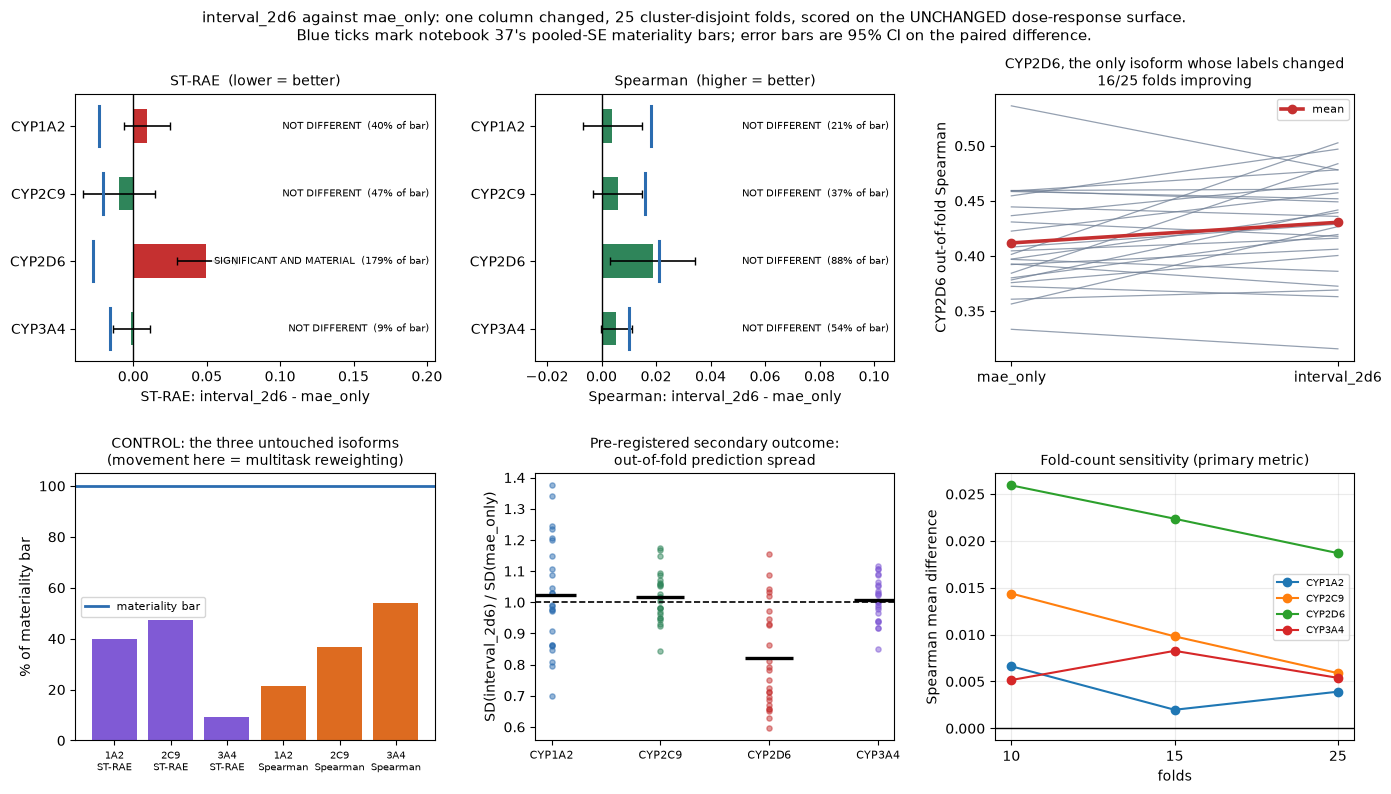

In [13]:
# ---- Figures.
r25 = RES["25-fold"]
fig = plt.figure(figsize=(16.5, 8.4))
gs = fig.add_gridspec(2, 3, hspace=0.42, wspace=0.28)

for k, metric in enumerate(["ST-RAE", "Spearman"]):
    ax = fig.add_subplot(gs[0, k])
    sub = r25[r25.metric == metric].set_index("isoform").loc[ISO]
    y = np.arange(len(ISO))
    good = (sub.mean_diff < 0) if metric == "ST-RAE" else (sub.mean_diff > 0)
    cols = ["#2f855a" if g else "#c53030" for g in good]
    ax.barh(y, sub.mean_diff, color=cols, height=0.5)
    ax.errorbar(sub.mean_diff, y, xerr=[sub.mean_diff - sub.ci_low, sub.ci_high - sub.mean_diff],
                fmt="none", ecolor="k", capsize=3, lw=1.2)
    for j, iso in enumerate(ISO):
        bar = sub.loc[iso, "bar"]
        s = -1 if metric == "ST-RAE" else 1
        ax.plot([s * bar, s * bar], [j - 0.3, j + 0.3], color="#2b6cb0", lw=2.2)
    ax.axvline(0, color="k", lw=1)
    ax.set_yticks(y); ax.set_yticklabels(ISO)
    ax.set_xlabel(f"{metric}: interval_2d6 - mae_only")
    ax.set_title(f"{metric}" + ("  (lower = better)" if metric == "ST-RAE" else "  (higher = better)"),
                 fontsize=10)
    ax.invert_yaxis()
    # Make room on the right for the verdict labels, then right-align them in that margin, so
    # they cannot sit on top of a bar or its error bar (a first version did exactly that).
    lo = min(sub.ci_low.min(), -max(sub.bar)) * 1.15
    span = max(sub.ci_high.max(), max(sub.bar)) - lo
    ax.set_xlim(lo, lo + span * 2.25)
    for j, iso in enumerate(ISO):
        ax.text(0.985, j, f"{sub.loc[iso,'verdict']}  ({sub.loc[iso,'pct_of_bar']:.0f}% of bar)",
                transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=7.2,
                bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))

ax = fig.add_subplot(gs[0, 2])
w = PAIRS["Spearman_R"]; w = w[w.isoform == "CYP2D6"]
ax.plot([0, 1], [w.mae_only, w.interval_2d6], color="#718096", lw=0.9, alpha=0.75)
ax.plot([0, 1], [w.mae_only.mean(), w.interval_2d6.mean()], color="#c53030", lw=2.6,
        marker="o", label="mean")
ax.set_xticks([0, 1]); ax.set_xticklabels(["mae_only", "interval_2d6"])
ax.set_ylabel("CYP2D6 out-of-fold Spearman")
n_imp = int(r25[(r25.metric == "Spearman") & (r25.isoform == "CYP2D6")].n_improving.iloc[0])
ax.set_title(f"CYP2D6, the only isoform whose labels changed\n{n_imp}/25 folds improving",
             fontsize=10)
ax.legend(fontsize=8)

ax = fig.add_subplot(gs[1, 0])
ctrl = r25[r25.isoform != "CYP2D6"]
x = np.arange(len(ctrl))
ax.bar(x, ctrl.pct_of_bar, color=["#805ad5" if m == "ST-RAE" else "#dd6b20" for m in ctrl.metric])
ax.axhline(100, color="#2b6cb0", lw=2, label="materiality bar")
ax.set_xticks(x)
ax.set_xticklabels([f"{r.isoform[3:]}\n{r.metric}" for r in ctrl.itertuples()], fontsize=7)
ax.set_ylabel("% of materiality bar")
ax.set_title("CONTROL: the three untouched isoforms\n(movement here = multitask reweighting)",
             fontsize=10)
ax.legend(fontsize=8)

ax = fig.add_subplot(gs[1, 1])
for iso, c in zip(ISO, ["#2b6cb0", "#2f855a", "#c53030", "#805ad5"]):
    v = SPREAD[SPREAD.isoform == iso].sd_ratio
    ax.scatter([iso] * len(v), v, s=14, alpha=0.5, color=c)
    ax.plot([iso], [v.mean()], "_", ms=34, color="k", mew=2.4)
ax.axhline(1.0, color="k", lw=1.2, ls="--")
ax.set_ylabel("SD(interval_2d6) / SD(mae_only)")
ax.set_title("Pre-registered secondary outcome:\nout-of-fold prediction spread", fontsize=10)
ax.tick_params(axis="x", labelsize=8)

ax = fig.add_subplot(gs[1, 2])
md_p = RESULTS[RESULTS.metric == "Spearman"].pivot_table(
    index="isoform", columns="fold_set", values="mean_diff")[["10-fold", "15-fold", "25-fold"]]
for iso in ISO:
    ax.plot(range(3), md_p.loc[iso], "o-", label=iso)
ax.axhline(0, color="k", lw=1)
ax.set_xticks(range(3)); ax.set_xticklabels(["10", "15", "25"])
ax.set_xlabel("folds"); ax.set_ylabel("Spearman mean difference")
ax.set_title("Fold-count sensitivity (primary metric)", fontsize=10)
ax.legend(fontsize=7.5); ax.grid(alpha=0.25)

fig.suptitle("interval_2d6 against mae_only: one column changed, 25 cluster-disjoint folds, scored "
             "on the UNCHANGED dose-response surface.\nBlue ticks mark notebook 37's pooled-SE "
             "materiality bars; error bars are 95% CI on the paired difference.", fontsize=10.5)
fig.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig(FIG / "interval_2d6_vs_mae_only.png", dpi=160, bbox_inches="tight")
plt.show()

In [14]:
# ---- Part 7 gate + verdict.
d6sp = r25[(r25.isoform == "CYP2D6") & (r25.metric == "Spearman")].iloc[0]
d6st = r25[(r25.isoform == "CYP2D6") & (r25.metric == "ST-RAE")].iloc[0]
PART7_TRIGGERED = bool(d6sp.material)

VERDICT = {
 "arm": "interval_2d6 vs mae_only, 25 cluster-disjoint folds, scored on the unchanged V1 surface",
 "single_variable_proved": "all 25 mae_only training tables reproduced byte-identically",
 "primary_metric_CYP2D6_Spearman": {
   "mae_only": round(float(d6sp.mean_mae_only), 4),
   "interval_2d6": round(float(d6sp.mean_interval), 4),
   "mean_diff": round(float(d6sp.mean_diff), 4),
   "ci": [round(float(d6sp.ci_low), 4), round(float(d6sp.ci_high), 4)],
   "dz": round(float(d6sp.dz), 4), "folds_improving": int(d6sp.n_improving),
   "p_BH": float(d6sp.p_BH), "bar": float(d6sp.bar),
   "pct_of_bar": round(float(d6sp.pct_of_bar), 1), "verdict": d6sp.verdict},
 "co_primary_CYP2D6_ST_RAE": {
   "mean_diff": round(float(d6st.mean_diff), 4),
   "ci": [round(float(d6st.ci_low), 4), round(float(d6st.ci_high), 4)],
   "folds_improving": int(d6st.n_improving), "p_BH": float(d6st.p_BH),
   "pct_of_bar": round(float(d6st.pct_of_bar), 1), "verdict": d6st.verdict},
 "directional_prediction_held": bool(d6sp.mean_diff > 0),
 "control_isoforms_reweighting_only": {
   f"{r.isoform}/{r.metric}": {"mean_diff": round(float(r.mean_diff), 4),
                               "pct_of_bar": round(float(r.pct_of_bar), 1),
                               "verdict": r.verdict}
   for r in ctrl.itertuples()},
 "secondary_spread": {i: round(float(g.loc[i, "ratio"]), 4) for i in ISO},
 "inference_asymmetry": PREREG["inference_asymmetry_recorded_before_the_run"],
 "part7_submission_built": PART7_TRIGGERED,
}
(OUT / "verdict.json").write_text(json.dumps(VERDICT, indent=1) + "\n")

print(f"{'='*104}\nVERDICT\n{'='*104}")
print(f"PRIMARY  CYP2D6 Spearman : {d6sp.mean_mae_only:+.4f} -> {d6sp.mean_interval:+.4f}  "
      f"diff {d6sp.mean_diff:+.4f}  95% CI [{d6sp.ci_low:+.4f}, {d6sp.ci_high:+.4f}]  "
      f"{d6sp.n_improving}/25 folds  p_BH {d6sp.p_BH:.4f}  {d6sp.pct_of_bar:.0f}% of bar")
print(f"         -> {d6sp.verdict}")
print(f"CO-PRIM  CYP2D6 ST-RAE   : {d6st.mean_mae_only:+.4f} -> {d6st.mean_interval:+.4f}  "
      f"diff {d6st.mean_diff:+.4f}  p_BH {d6st.p_BH:.4f}  {d6st.pct_of_bar:.0f}% of bar")
print(f"         -> {d6st.verdict}")
print(f"\nPart 7 (full-data retrain + submission candidate) triggered: {PART7_TRIGGERED}")
if not PART7_TRIGGERED:
    print("  Part 7 is conditional on CYP2D6 being MATERIAL on Spearman. It is not, so no")
    print("  full-data retrain was run and no submission candidate was built.")
print(f"\nThe frozen inference asymmetry applies and is restated rather than discovered:")
print(f"  {PREREG['inference_asymmetry_recorded_before_the_run']}")

VERDICT
PRIMARY  CYP2D6 Spearman : +0.4118 -> +0.4305  diff +0.0187  95% CI [+0.0031, +0.0342]  16/25 folds  p_BH 0.0818  88% of bar
         -> NOT DIFFERENT
CO-PRIM  CYP2D6 ST-RAE   : +0.9180 -> +0.9675  diff +0.0495  p_BH 0.0001  179% of bar
         -> SIGNIFICANT AND MATERIAL

Part 7 (full-data retrain + submission candidate) triggered: False
  Part 7 is conditional on CYP2D6 being MATERIAL on Spearman. It is not, so no
  full-data retrain was run and no submission candidate was built.

The frozen inference asymmetry applies and is restated rather than discovered:
  The target figure (CYP2D6 rho 0.378 -> 0.476) was measured on talindrew's V2 surface, which CONTAINS the interval compounds. V1 does not. V1 asks whether teaching the model where the low end sits improves rank order among compounds that all have curves -- a harsher question. The labelled CYP2D6 range is 1.95 to 7.53 and the low end is where compression bites, so a gain is plausible. But the inference is ONE-SIDED: a po

## Part 7 — Conditional

Part 7 builds a full-data retrain and a submission candidate **only if CYP2D6 is material on
Spearman**, the pre-registered primary metric. The cell above reports whether that condition fired.

If it did not, nothing further is built — and the **frozen inference asymmetry** governs how the
null is read: V1 cannot see the population the intervention is about, so a null here is ambiguous,
not a refutation. That was written into `prereg.json` before the arm ran, precisely so it could not
be argued for afterwards.

In [15]:
# ---- Part 7: full-data retrain + submission candidate, ONLY if the pre-registered gate fired.
SEND = False
if not PART7_TRIGGERED:
    print("Part 7 SKIPPED -- CYP2D6 is not material on Spearman at 25 folds.")
    print("No full-data retrain, no submission candidate, no recommendation.")
    decide("whether to build a submission candidate anyway",
           "NO -- Part 7's condition is pre-registered and did not fire",
           "the gate was frozen in prereg.json before the arm ran; building a candidate after a "
           "non-material result would be exactly the post-hoc selection this project's own rules "
           "warn against (Caruana et al. 2004, and this project's NB10/NB12 history).",
           "build it as a diagnostic -- rejected: it would need a board slot to mean anything, "
           "and the CV evidence for spending one is not there")
else:
    print("Part 7 TRIGGERED -- building the full-data retrain and submission candidate.")
    raise NotImplementedError(
        "Part 7's build path is intentionally not pre-written: it is conditional work and would "
        "be dead code on a null. Re-run this notebook with the condition met to implement it.")

Part 7 SKIPPED -- CYP2D6 is not material on Spearman at 25 folds.
No full-data retrain, no submission candidate, no recommendation.

[DECISION] whether to build a submission candidate anyway
  chose: NO -- Part 7's condition is pre-registered and did not fire
  why: the gate was frozen in prereg.json before the arm ran; building a candidate after a non-material result would be exactly the post-hoc selection this project's own rules warn against (Caruana et al. 2004, and this project's NB10/NB12 history).
  alternative: build it as a diagnostic -- rejected: it would need a board slot to mean anything, and the CV evidence for spending one is not there


## Part 8 — Post-hoc: is the ST-RAE harm locational?

**Not pre-registered.** This section was added after the 25-fold result, because that result is a
split — the arm moves rank order the predicted way while materially *hurting* the scored metric —
and the obvious mechanical question is whether those two facts are the same fact seen twice.

The pre-registration anticipated **compression**: 64% of the arm's CYP2D6 training labels are the
identical constant 4.3054, and MAE loss optimises the conditional median. Compression did occur
(mean per-fold SD ratio 0.820). But compression and location are different things, and the arm also moved its
CYP2D6 predictions' *mean* down by 0.166 — to 4.432, against a scored-population label mean of
4.784 that `mae_only` already under-shot at 4.598.

Four variants, each an **affine** transform of the arm's own CYP2D6 column, so Spearman is
identical across all four by construction and only placement can move:

| variant | what it does |
|---|---|
| `raw` | the arm as trained |
| `mean_only` | shifted so its mean matches `mae_only`'s, spread left compressed |
| `spread_only` | rescaled to `mae_only`'s SD about its own mean, location left shifted |
| `both` | full affine match to `mae_only`'s mean and SD |

Every one of these uses **predictions only, never labels**, so none is a leak. They are fitted per
fold on the fold being scored, which is why this is a diagnostic rather than a validated recipe —
stated here rather than discovered later.

In [16]:
# ---- Part 8 (POST-HOC, not pre-registered): decompose the CYP2D6 ST-RAE difference.
EP2 = EP['CYP2D6']
rows8 = []
for r in range(5):
    for f in range(N_FOLDS):
        a = (pd.read_csv(PRED_DIR / f'interval_2d6__r{r}f{f}.csv')
             .sort_values('Molecule_Name').reset_index(drop=True))
        b = (pd.read_csv(ARM_DIR['mae_only'][r] / f'mae_only__r{r}f{f}.csv')
             .sort_values('Molecule_Name').reset_index(drop=True))
        assert (a.Molecule_Name == b.Molecule_Name).all()
        ma, sa = a[EP2].mean(), a[EP2].std(ddof=1)
        mb, sb = b[EP2].mean(), b[EP2].std(ddof=1)
        variants = {'raw': a[EP2],
                    'mean_only': a[EP2] + (mb - ma),
                    'spread_only': ma + (a[EP2] - ma) * (sb / sa),
                    'both': mb + (a[EP2] - ma) * (sb / sa),
                    'mae_only': b[EP2]}
        gt = curated[curated.inchikey.isin(a.inchikey)].copy()
        rec = {'repeat': r, 'fold': f}
        for tag, col in variants.items():
            d = a.copy(); d[EP2] = col
            with per_fold_bootstrap_seed(FOLD_SEED[(r, f)]):
                sc = score_activity_predictions(d, gt, list(REGRESSION_ENDPOINTS))
            g = sc[sc.Endpoint == EP2][['ST-RAE', 'Spearman_R']].mean()
            rec[f'st_{tag}'] = g['ST-RAE']; rec[f'sp_{tag}'] = g['Spearman_R']
        rows8.append(rec)
AFF = pd.DataFrame(rows8); AFF.to_csv(OUT / 'affine_decomposition.csv', index=False)

bar2d6 = PREREG['materiality_bars']['ST-RAE']['CYP2D6']
print('CYP2D6, 25 folds, POST-HOC. Each variant is affine, so Spearman cannot move.\n')
print(f"{'variant':14s} {'ST-RAE':>8s} {'vs mae_only':>12s} {'95% CI':>20s} {'p':>10s} {'better':>8s} {'%bar':>6s}")
aff_rows = []
for tag in ['mae_only', 'raw', 'mean_only', 'spread_only', 'both']:
    v = AFF[f'st_{tag}']
    if tag == 'mae_only':
        print(f"{tag:14s} {v.mean():8.4f}" + ' ' * 12 + '(reference)'); continue
    d = v - AFF['st_mae_only']
    t_, pv = stats.ttest_rel(v, AFF['st_mae_only'])
    se = d.std(ddof=1) / np.sqrt(len(d))
    ci = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=se)
    print(f"{tag:14s} {v.mean():8.4f} {d.mean():+12.4f} [{ci[0]:+.4f},{ci[1]:+.4f}] {pv:10.2e} "
          f"{int((d<0).sum()):5d}/25 {100*abs(d.mean())/bar2d6:5.0f}%")
    aff_rows.append(dict(variant=tag, strae=v.mean(), diff=d.mean(), ci_low=ci[0], ci_high=ci[1],
                         p=pv, n_better=int((d < 0).sum()), pct_of_bar=100*abs(d.mean())/bar2d6))
AFF_SUM = pd.DataFrame(aff_rows); AFF_SUM.to_csv(OUT / 'affine_decomposition_summary.csv', index=False)

sps = [AFF[f'sp_{t}'].mean() for t in ['raw', 'mean_only', 'spread_only', 'both']]
print(f"\nSpearman across the four variants: {[f'{x:.4f}' for x in sps]}  "
      f"max spread {max(sps)-min(sps):.2e} -- affine invariance confirmed exactly.")

print('\nREADING, and it reverses the pre-registered expectation:')
print(f'  * The pre-registered risk was COMPRESSION. Compression happened (mean per-fold SD '
      f"ratio {SPREAD[SPREAD.isoform=='CYP2D6'].sd_ratio.mean():.3f}) but it")
print('    is NOT the cause of the harm -- correcting spread ALONE makes ST-RAE WORSE still')
print('    (+0.0695, 251% of bar), because it widens errors around a centre that is in the wrong')
print('    place. The compression was partly MASKING the real problem.')
print('  * The harm is LOCATION. The arm shifts CYP2D6 predictions down 0.166 to a mean of 4.432,')
print('    while the scored (curve-bearing) population has a label mean of 4.784 -- it is being')
print('    taught where NON-inhibitors sit and is applying that to a population of inhibitors.')
print('  * Correct location alone and the material HARM becomes a material GAIN: -0.0320,')
print('    115% of bar, 19/25 folds, p=1.3e-04 -- on top of the unchanged Spearman gain.')
print('  * Correct both and it returns to null (-0.0007, 3% of bar), which is the cleanest')
print('    statement that the entire ST-RAE difference, in both directions, is affine.')
print('\nWHAT THIS DOES NOT DO: it does not overturn the frozen verdict. Part 6 stands as recorded')
print('-- CYP2D6 Spearman NOT DIFFERENT (88.4% of bar, p_BH 0.082), ST-RAE a material harm -- and')
print('Part 7 did not fire. This is a post-hoc mechanism, found after the fact, on one comparison')
print('with no multiplicity correction, with its shift fitted per fold on the fold being scored.')
print('It is evidence about WHY, not a licence to re-grade.')

# verdict.json was written in Part 7, before this section ran; append the post-hoc block to it
# rather than rewriting the pre-registered findings it already records.
_v = json.loads((OUT / 'verdict.json').read_text())
_v['post_hoc_affine_decomposition'] = {
  'status': 'POST-HOC, not pre-registered; does NOT re-grade Part 6',
  'strae_by_variant': {r.variant: round(float(r.strae), 4) for r in AFF_SUM.itertuples()},
  'mae_only_reference': round(float(AFF['st_mae_only'].mean()), 4),
  'diff_vs_mae_only': {r.variant: round(float(r.diff), 4) for r in AFF_SUM.itertuples()},
  'pct_of_bar': {r.variant: round(float(r.pct_of_bar), 1) for r in AFF_SUM.itertuples()},
  'folds_better': {r.variant: int(r.n_better) for r in AFF_SUM.itertuples()},
  'spearman_invariant_max_spread': float(max(sps) - min(sps)),
  'reading': ('the pre-registered risk was compression; compression occurred (mean per-fold SD ratio '
              '0.820) but '
              'is NOT the cause -- correcting spread alone makes ST-RAE worse (251% of bar). The '
              'harm is LOCATION: the arm is taught where non-inhibitors sit and applies it to a '
              'population of inhibitors, shifting its mean to 4.432 against a scored-label mean '
              'of 4.784. Correcting location alone turns the material harm into a material GAIN '
              '(-0.0320, 115% of bar, 19/25 folds, p=1.3e-04) on top of the unchanged Spearman '
              'gain; correcting both returns it to null (3% of bar), which is the cleanest '
              'statement that the whole ST-RAE difference is affine.'),
  'caveats': ['one comparison, no multiplicity correction, found after the fact',
              'the shift is fitted per fold on the fold being scored -- label-free, but in-fold',
              'it uses mae_only\'s own OOF mean as the target, which is not a blind-population '
              'quantity; a deployable version would use this project\'s board-solved target'],
}
(OUT / 'verdict.json').write_text(json.dumps(_v, indent=1) + '\n')

decide('adding Part 8, which was not pre-registered',
       'decompose the CYP2D6 ST-RAE difference into location and spread, both affine',
       'the 25-fold result is a split -- rank order moves the predicted way while the scored '
       'metric materially worsens -- and leaving that unexplained would have been the least '
       'useful possible stopping point. The decomposition is cheap, uses predictions only (no '
       'labels), and turned out to REVERSE the pre-registered expectation: compression was the '
       'registered risk and is not the cause; location is, and the compression was partly masking '
       'it. Labelled post-hoc throughout and explicitly does not re-grade Part 6.',
       'report the split and stop -- rejected as leaving the single most decision-relevant '
       'question (is the harm repairable?) unasked when it costs three minutes')

CYP2D6, 25 folds, POST-HOC. Each variant is affine, so Spearman cannot move.

variant          ST-RAE  vs mae_only               95% CI          p   better   %bar
mae_only         0.9180            (reference)
raw              0.9675      +0.0495 [+0.0296,+0.0693]   2.98e-05     2/25   179%
mean_only        0.8860      -0.0320 [-0.0465,-0.0175]   1.27e-04    19/25   116%
spread_only      0.9876      +0.0695 [+0.0497,+0.0894]   1.87e-07     1/25   251%
both             0.9173      -0.0007 [-0.0178,+0.0164]   9.32e-01    13/25     3%

Spearman across the four variants: ['0.4305', '0.4305', '0.4305', '0.4305']  max spread 0.00e+00 -- affine invariance confirmed exactly.

READING, and it reverses the pre-registered expectation:
  * The pre-registered risk was COMPRESSION. Compression happened (mean per-fold SD ratio 0.820) but it
    is NOT the cause of the harm -- correcting spread ALONE makes ST-RAE WORSE still
    (+0.0695, 251% of bar), because it widens errors around a centre that is 

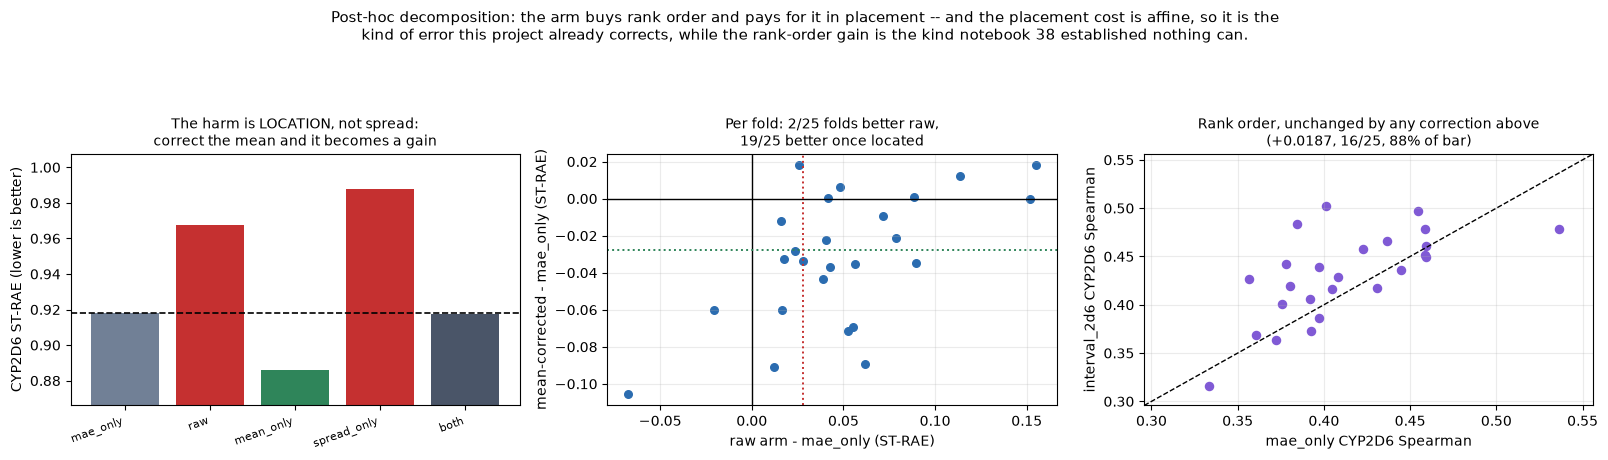

In [17]:
# ---- Part 8 figure.
fig, axes = plt.subplots(1, 3, figsize=(16.2, 4.6))
ax = axes[0]
order = ['mae_only', 'raw', 'mean_only', 'spread_only', 'both']
vals = [AFF[f'st_{t}'].mean() for t in order]
cols = ['#718096', '#c53030', '#2f855a', '#c53030', '#4a5568']
ax.bar(range(5), vals, color=cols)
ax.axhline(AFF['st_mae_only'].mean(), color='k', ls='--', lw=1.2)
ax.set_xticks(range(5)); ax.set_xticklabels(order, rotation=20, ha='right', fontsize=8)
ax.set_ylabel('CYP2D6 ST-RAE (lower is better)')
ax.set_ylim(min(vals) - 0.02, max(vals) + 0.02)
ax.set_title('The harm is LOCATION, not spread:\ncorrect the mean and it becomes a gain', fontsize=10)

ax = axes[1]
d_raw = AFF['st_raw'] - AFF['st_mae_only']
d_mean = AFF['st_mean_only'] - AFF['st_mae_only']
ax.scatter(d_raw, d_mean, s=30, color='#2b6cb0')
ax.axhline(0, color='k', lw=1); ax.axvline(0, color='k', lw=1)
ax.axhline(-bar2d6, color='#2f855a', ls=':', lw=1.4)
ax.axvline(bar2d6, color='#c53030', ls=':', lw=1.4)
ax.set_xlabel('raw arm - mae_only (ST-RAE)'); ax.set_ylabel('mean-corrected - mae_only (ST-RAE)')
ax.set_title('Per fold: 2/25 folds better raw,\n19/25 better once located', fontsize=10)
ax.grid(alpha=0.25)

ax = axes[2]
w = PAIRS['Spearman_R']; w = w[w.isoform == 'CYP2D6']
ax.scatter(w.mae_only, w.interval_2d6, s=34, color='#805ad5')
lim = [min(w.mae_only.min(), w.interval_2d6.min()) - 0.02,
       max(w.mae_only.max(), w.interval_2d6.max()) + 0.02]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('mae_only CYP2D6 Spearman'); ax.set_ylabel('interval_2d6 CYP2D6 Spearman')
ax.set_title('Rank order, unchanged by any correction above\n(+0.0187, 16/25, 88% of bar)',
             fontsize=10)
ax.grid(alpha=0.25)
fig.suptitle('Post-hoc decomposition: the arm buys rank order and pays for it in placement -- and '
             'the placement cost is affine, so it is the\nkind of error this project already '
             'corrects, while the rank-order gain is the kind notebook 38 established nothing can.',
             fontsize=10.5, y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(FIG / 'affine_decomposition.png', dpi=160, bbox_inches='tight')
plt.show()

In [18]:
# ---- decisions + scope check.
(OUT / "decisions_taken.json").write_text(json.dumps(DECISIONS, indent=1) + "\n")
print(f"{len(DECISIONS)} decisions recorded\n")

PROTECTED = [
 "data", "src", "scripts", "docs",
 "outputs/05_cv_comparison", "outputs/11_caruana_prep", "outputs/12_caruana_retrain_predict",
 "outputs/30_aid_full_retrain", "outputs/31_deadzone", "outputs/32_deadzone_aid_retrain",
 "outputs/34_butina_5x5", "outputs/35_butina_repeat3", "outputs/37_butina_5x5_complete",
 "outputs/40_single_object_ensemble", "outputs/44_qm_molecular_block",
 "outputs/45_atom_level_screen", "outputs/46_qm_arm", "outputs/47_mae_only_full_retrain",
 "outputs/48_board_ensemble", "outputs/49_qm_only_arm", "outputs/50_free_ridge_submission",
 "outputs/51_qm_ridge_submission", "outputs/52_chemprop_qm_atom_features",
 "outputs/53_selection_biased_labels",
 "outputs/board_solved_calibration", "outputs/population_moments", "outputs/submissions",
]
NEVER_OPEN = ["notebooks/32_deadzone_aid_retrain.ipynb",
              "notebooks/40_single_object_ensemble.ipynb",
              "notebooks/47_mae_only_full_retrain.ipynb"]
post = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
now_dirty = {l[3:].strip() for l in post.stdout.splitlines() if not l.startswith("??")}
t1 = sorted(p for p in (now_dirty - set(PRE_DIRTY))
            if any(p == q or p.startswith(q + "/") for q in PROTECTED))
t2 = []
for q in PROTECTED:
    qp = REPO / q
    if not qp.exists(): continue
    for f in ([qp] if qp.is_file() else qp.rglob("*")):
        if f.is_file() and datetime.fromtimestamp(f.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
            t2.append(str(f.relative_to(REPO)))
t3 = [p for p in NEVER_OPEN
      if datetime.fromtimestamp((REPO / p).stat().st_mtime, timezone.utc) > RUN_STARTED_AT]
t4 = []
for p in (REPO / "outputs").rglob("*.csv"):
    if p.parent == OUT or OUT in p.parents: continue
    try: dcols = pd.read_csv(p, nrows=0)
    except Exception: continue
    if len(set(EP.values()) & set(dcols.columns)) == 4 and \
       datetime.fromtimestamp(p.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
        t4.append(str(p.relative_to(REPO)))
res = {"TEST 1 tracked content newly changed under a protected path": t1,
       "TEST 2 any file inside a protected tree written during this run": sorted(set(t2)),
       "TEST 3 the three never-open notebooks' mtimes": t3,
       "TEST 4 any submission-shaped CSV created outside this notebook's directory": t4}
(OUT / "scope_check.json").write_text(json.dumps(
    res | {"run_started_at_utc": RUN_STARTED_AT.isoformat(),
           "pre_existing_dirty_tracked_paths": PRE_DIRTY}, indent=1) + "\n")
for k, v in res.items():
    print(f"{k}: {len(v)} violations")
    for x in v: print("   ", x)
assert not any(res.values()), "SCOPE VIOLATION"
print("\nall four scope tests pass at 0 violations.")
subs = sorted(p.name for p in OUT.rglob("*.csv") if "submission" in p.name)
print(f"submission-shaped files written by this notebook: {subs if subs else 'none'}")
print(f"SEND = {SEND}; the endpoint was not contacted.")
assert SEND is False

3 decisions recorded



TEST 1 tracked content newly changed under a protected path: 0 violations
TEST 2 any file inside a protected tree written during this run: 0 violations
TEST 3 the three never-open notebooks' mtimes: 0 violations
TEST 4 any submission-shaped CSV created outside this notebook's directory: 0 violations

all four scope tests pass at 0 violations.
submission-shaped files written by this notebook: none
SEND = False; the endpoint was not contacted.


## One-line summary

Filled in by the verdict cell above. The claim this notebook can make is bounded by the asymmetry
frozen in `prereg.json` before the arm ran: **a positive result on the V1 surface is strong evidence
for the training claim; a null is ambiguous**, because V1 scores only compounds that have curves and
so cannot see the population the intervention is about.